In [1]:
## Charger le fichier nettoyé
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

projet = Path(r"C:\Projets\permis-quebec")
df = pd.read_csv(projet / "data" / "clean" / "permis_clean.csv", parse_dates=["DATE_DELIVRANCE"])
(projet / "reports" / "figures").mkdir(parents=True, exist_ok=True)
len(df)

69309

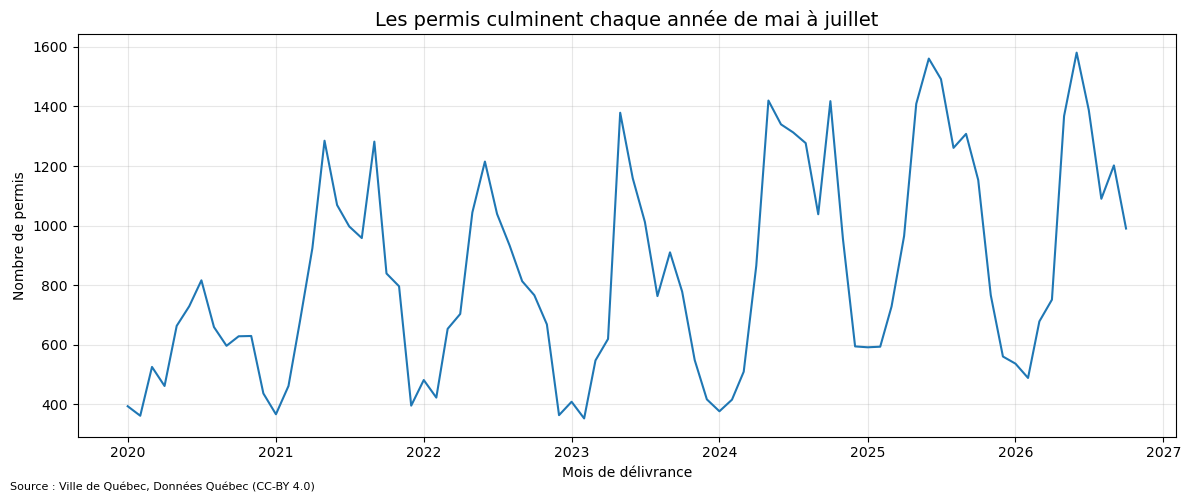

In [2]:
par_mois = df.groupby("mois").size()
par_mois = par_mois[par_mois.index < "2026-11"]   # novembre 2026 est incomplet

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(pd.to_datetime(par_mois.index), par_mois.values, color="#1f77b4")
ax.set_title("Les permis culminent chaque année de mai à juillet", fontsize=14)
ax.set_xlabel("Mois de délivrance")
ax.set_ylabel("Nombre de permis")
ax.grid(alpha=0.3)
fig.text(0.01, 0.01, "Source : Ville de Québec, Données Québec (CC-BY 4.0)", fontsize=8)
fig.tight_layout()
fig.savefig(projet / "reports" / "figures" / "01_evolution_mensuelle.png", dpi=150)
plt.show()

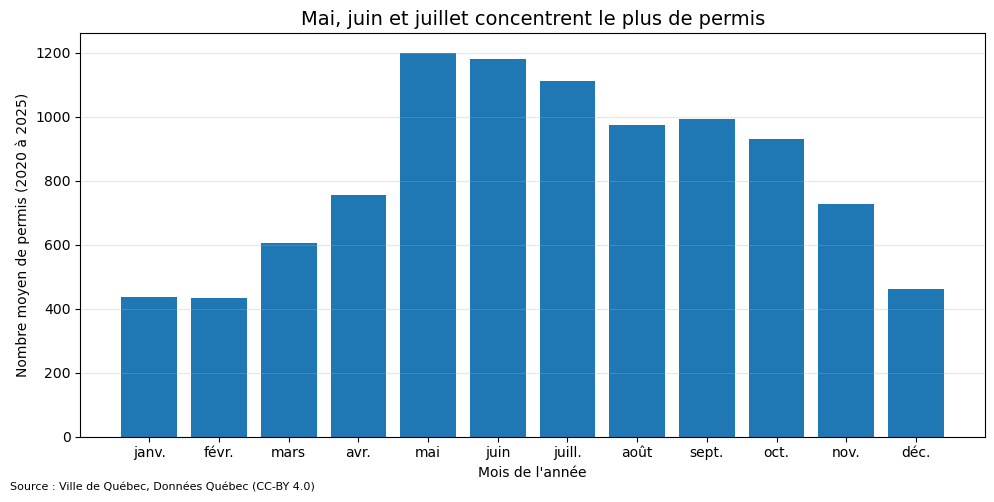

In [3]:
complet = df[df["annee"] <= 2025]          # 2026 est incomplète
par_mois_annee = complet.groupby(["annee", complet["DATE_DELIVRANCE"].dt.month]).size()
moyenne = par_mois_annee.groupby(level=1).mean()

noms = ["janv.", "févr.", "mars", "avr.", "mai", "juin",
        "juill.", "août", "sept.", "oct.", "nov.", "déc."]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(noms, moyenne.values, color="#1f77b4")
ax.set_title("Mai, juin et juillet concentrent le plus de permis", fontsize=14)
ax.set_xlabel("Mois de l'année")
ax.set_ylabel("Nombre moyen de permis (2020 à 2025)")
ax.grid(axis="y", alpha=0.3)
fig.text(0.01, 0.01, "Source : Ville de Québec, Données Québec (CC-BY 4.0)", fontsize=8)
fig.tight_layout()
fig.savefig(projet / "reports" / "figures" / "02_saisonnalite.png", dpi=150)
plt.show()

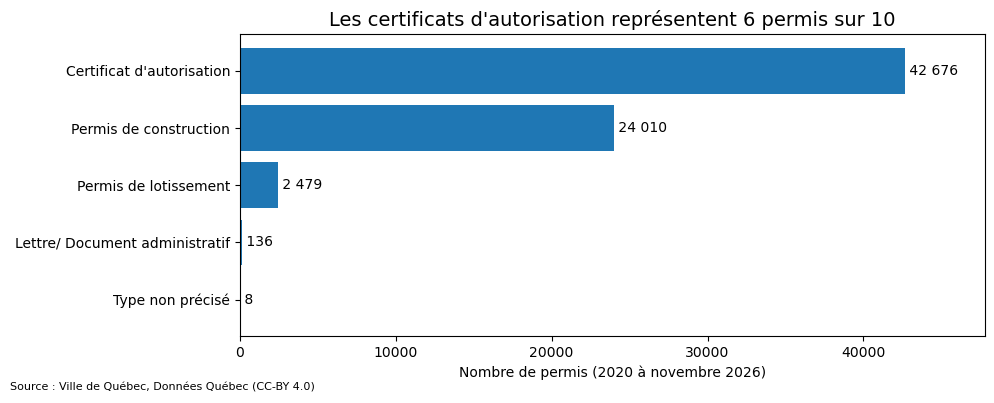

In [4]:
## la répartition par type de permis
par_type = df["TYPE_PERMIS"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(par_type.index, par_type.values, color="#1f77b4")
ax.set_title("Les certificats d'autorisation représentent 6 permis sur 10", fontsize=14)
ax.set_xlabel("Nombre de permis (2020 à novembre 2026)")
for position, valeur in enumerate(par_type.values):
    ax.text(valeur, position, f" {valeur:,}".replace(",", " "), va="center")
ax.set_xlim(0, par_type.max() * 1.12)
fig.text(0.01, 0.01, "Source : Ville de Québec, Données Québec (CC-BY 4.0)", fontsize=8)
fig.tight_layout()
fig.savefig(projet / "reports" / "figures" / "03_types_permis.png", dpi=150)
plt.show()

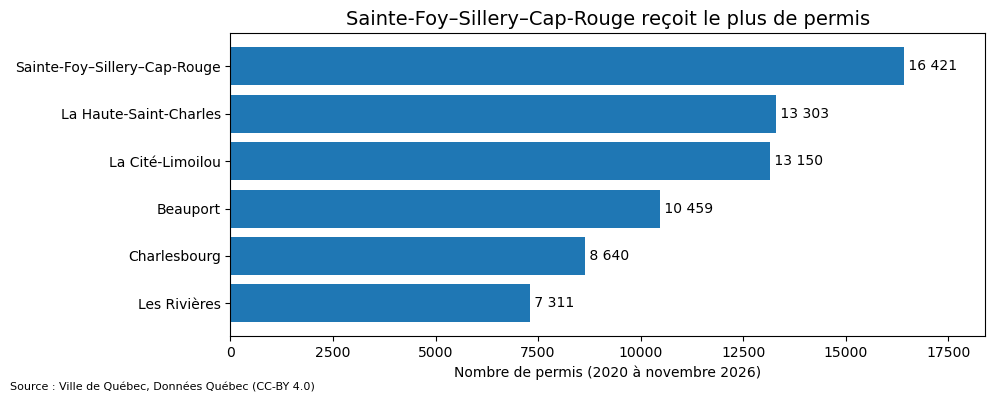

In [5]:
## Les arrondissements
arr = df[df["ARRONDISSEMENT"] != "Hors arrondissements"]
par_arr = arr["ARRONDISSEMENT"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(par_arr.index, par_arr.values, color="#1f77b4")
ax.set_title("Sainte-Foy–Sillery–Cap-Rouge reçoit le plus de permis", fontsize=14)
ax.set_xlabel("Nombre de permis (2020 à novembre 2026)")
for position, valeur in enumerate(par_arr.values):
    ax.text(valeur, position, f" {valeur:,}".replace(",", " "), va="center")
ax.set_xlim(0, par_arr.max() * 1.12)
fig.text(0.01, 0.01, "Source : Ville de Québec, Données Québec (CC-BY 4.0)", fontsize=8)
fig.tight_layout()
fig.savefig(projet / "reports" / "figures" / "04_arrondissements.png", dpi=150)
plt.show()